In [139]:
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd
from matplotlib_scalebar.scalebar import ScaleBar
from shapely.geometry import Point

ox.settings.use_cache = True
ox.settings.log_console = True

In [15]:
downtown = gpd.read_file("data/downtown.geojson").set_crs(4326).to_crs(23700)
downtown_poly = downtown.geometry[0]
blocks = gpd.read_file("data/house_blocks.geojson").set_crs(4326).to_crs(23700)

<Axes: >

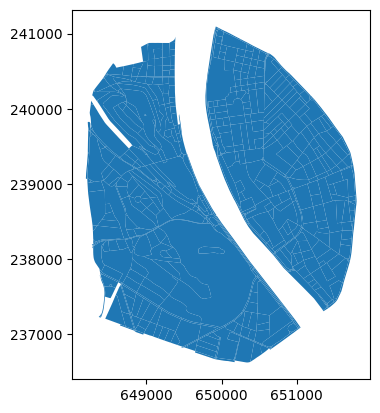

In [27]:
blocks[blocks.geometry.within(downtown.geometry[0])].plot()

<Axes: >

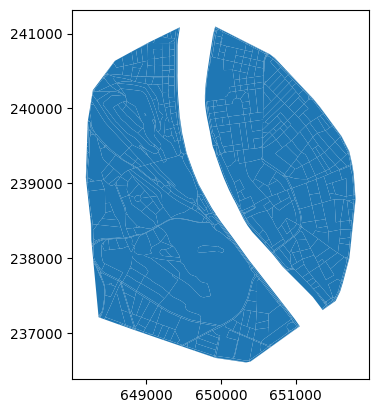

In [28]:
gpd.clip(blocks[blocks.geometry.intersects(downtown_poly)], downtown_poly).plot()

In [47]:
bridge_names = [
    "Margit híd",
    "Széchenyi lánchíd",
    "Erzsébet híd",
    "Szabadság híd",
    "Petőfi híd",
]
bridges = ox.features_from_polygon(
    downtown.to_crs(4326).geometry[0], tags={"name": bridge_names}
)
bridges["is_point"] = bridges["geometry"].apply(isinstance, args=(Point,))
bridges = bridges.query("~is_point")
bridges.to_crs(23700, inplace=True)

In [119]:
g = ox.graph_from_polygon(downtown.envelope.to_crs(4326).geometry[0], retain_all=True)
streets = ox.graph_to_gdfs(g, nodes=False)
streets.to_crs(23700, inplace=True)

g = ox.graph_from_polygon(downtown.buffer(0).to_crs(4326).geometry[0], retain_all=True)
downtown_streets = ox.graph_to_gdfs(g, nodes=False)
downtown_streets.to_crs(23700, inplace=True)

# duna = ox.features_from_polygon(
#     downtown.envelope.buffer(100).to_crs(4326).geometry[0], tags={"name": "Duna"}
# )
# duna_ = gpd.clip(gpd.GeoSeries(duna.union_all(), crs=4326).to_crs(23700), downtown.envelope).to_crs(23700)
land = gpd.GeoSeries(downtown_poly.envelope.difference(duna.union_all()))

In [126]:
# duna = gpd.read_file("../data/duna_agglomeration.geojson").set_crs(4326).to_crs(23700)
duna = gpd.read_file(
    "/home/gergo/NETI/code/barriers_in_cities/papers/mobility-neighborhood-barriers/data/duna_agglomeration.geojson"
).to_crs(23700)

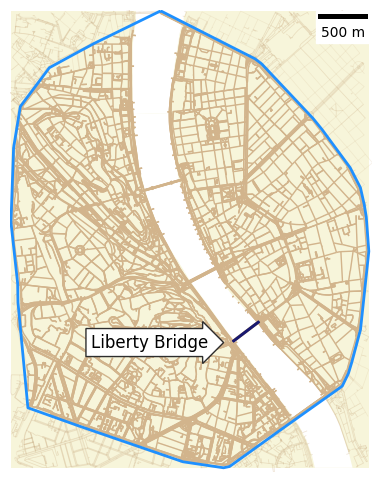

In [140]:
c_land = "#eee8aa6f"
c_street = "#d2b48c"
c_ping = "#874312"
c_stop = "#191970"
c_block = "#1e90ff"
fig, ax = plt.subplots(figsize=(5, 6))
land.plot(ax=ax, color=c_land, zorder=0)
gpd.clip(duna, downtown.envelope).plot(ax=ax, fc="white", ec="none", zorder=1)

streets.plot(ax=ax, color=c_street, lw=0.5, alpha=0.2, zorder=2)
downtown_streets.plot(ax=ax, color=c_street, lw=1, zorder=3)
ax.margins(0)
bridges.query("~name.isin(['Szabadság híd', 'Margit híd'])").plot(
    ax=ax, color=c_street, zorder=4
)
bridges.query("name=='Szabadság híd'").plot(ax=ax, color=c_stop, zorder=5)
downtown.plot(ax=ax, fc="none", ec=c_block, lw=2, zorder=10)
ax.text(
    649000,
    237815,
    "Liberty Bridge",
    fontsize=12,
    bbox=dict(boxstyle="rarrow", ec="#2d2d2d", fc="#ffffff"),
)
ax.add_artist(ScaleBar(1))
ax.axis("off")
for i in [".png"]:
    fig.savefig(
        f"liberty_bridge.{i}",
        dpi=300,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0,
    )

In [40]:
targets = [
    "2019-06-01_2019-06-02",
    "2019-06-08_2019-06-09",
    "2019-06-15_2019-06-16",
    "2019-06-22_2019-06-23",
    "2019-06-29_2019-06-30",
    "2019-07-06_2019-07-07",
    "2019-07-13_2019-07-14",
    "2019-07-20_2019-07-21",
    "2019-07-27_2019-07-28",
    "2019-08-03_2019-08-04",
    "2019-08-10_2019-08-11",
]
for target in targets:
    data = pd.read_csv(f"data/place_connections_{target}.csv")
    in_area = blocks[blocks.geometry.intersects(downtown_poly)].copy()
    data[
        (data["target"].isin(in_area["id"])) & (data["source"].isin(in_area["id"]))
    ].to_csv(f"data/place_connections_{target}_downtown.csv", index=False)